# NYC Taxi Data Pipeline: Trip Activity Analytics
## Teresa Ferrill
### October 8, 2026

This notebook uses the processed January 2025 dataset to summarize recorded trip activity by pickup date, hour, and borough.  

Counts include flagged January records. They describe recorded activity, not verified completed trips or total transportation demand.  

Run Notebook 02 first to generate the processed Parquet file.  Run this notebook from the notebooks folder.   

### load and verify the processed data

In [1]:
from pathlib import Path
import pandas as pd

processed_path = Path(
    "../data/processed/yellow_trips_2025-01_processed.parquet"
)

if not processed_path.exists():
    raise FileNotFoundError(
        "Run 02_Data_Processing.ipynb first to generate the processed file."
    )

# Load only the columns needed for these summaries.
activity = pd.read_parquet(
    processed_path,
    columns=[
        "source_file",
        "source_row",
        "tpep_pickup_datetime",
        "pickup_borough",
        "flag_unmatched_pickup"
    ]
)

pickup = activity["tpep_pickup_datetime"]

assert pickup.notna().all()
assert (
    pickup.ge(pd.Timestamp("2025-01-01"))
    & pickup.lt(pd.Timestamp("2025-02-01"))
).all()

assert not activity.duplicated(
    subset=["source_file", "source_row"]
).any()

print(f"January records loaded: {len(activity):,}")

January records loaded: 3,475,204


### 1. Summarize Recorded Trip Activity

Daily and hourly counts use the supplied pickup timestamps.
Borough summaries preserve unknown or unavailable location categories.

Each summary must reconcile to the total number of January records.

In [2]:
activity["pickup_date"] = pickup.dt.normalize()
activity["pickup_hour"] = pickup.dt.hour

daily_counts = (
    activity.groupby("pickup_date")
    .size()
    .reindex(
        pd.date_range("2025-01-01", "2025-01-31"),
        fill_value=0
    )
    .rename("record_count")
    .rename_axis("pickup_date")
    .reset_index()
)

hourly_counts = (
    activity.groupby("pickup_hour")
    .size()
    .reindex(range(24), fill_value=0)
    .rename("record_count")
    .rename_axis("pickup_hour")
    .reset_index()
)

# Preserve missing descriptions rather than dropping those records.
borough_labels = activity["pickup_borough"].fillna(
    "Missing borough description"
)

borough_counts = (
    borough_labels.value_counts()
    .rename_axis("pickup_borough")
    .reset_index(name="record_count")
)

borough_counts["percent_of_records"] = (
    borough_counts["record_count"] / len(activity) * 100
).round(2)

for summary in [daily_counts, hourly_counts, borough_counts]:
    assert summary["record_count"].sum() == len(activity)

print("Daily activity")
display(daily_counts.head())

print("Hourly activity")
display(hourly_counts)

print("Pickup borough activity")
display(borough_counts)

print("Five dates with the most records")
display(daily_counts.nlargest(5, "record_count"))

Daily activity


,pickup_date,record_count
0,2025-01-01,90188
1,2025-01-02,84832
2,2025-01-03,91250
3,2025-01-04,97804
4,2025-01-05,79624


Hourly activity


,pickup_hour,record_count
0,0,93416
1,1,64484
2,2,43929
3,3,28492
4,4,20033
5,5,22551
6,6,50026
7,7,102581
8,8,141305
9,9,142877


Pickup borough activity


,pickup_borough,record_count,percent_of_records
0,Manhattan,3089258,88.89
1,Queens,294981,8.49
2,Brooklyn,66070,1.90
3,Bronx,14741,0.42
4,Unknown,8141,0.23
5,Missing borough description,1380,0.04
6,EWR,377,0.01
7,Staten Island,256,0.01


Five dates with the most records


,pickup_date,record_count
15,2025-01-16,138711
22,2025-01-23,138136
24,2025-01-25,136816
30,2025-01-31,133579
29,2025-01-30,133266


In [3]:
report_dir = Path("../reports")
report_dir.mkdir(parents=True, exist_ok=True)

summaries = {
    "daily_trip_counts_2025-01.csv": daily_counts,
    "hourly_trip_counts_2025-01.csv": hourly_counts,
    "pickup_borough_counts_2025-01.csv": borough_counts
}

for filename, summary in summaries.items():
    output_path = report_dir / filename
    summary.to_csv(output_path, index=False)
    print(f"Saved: {output_path.resolve()}")

Saved: C:\Users\ferri\anaconda_projects\DSC680\Week_09\NYC_Taxi\reports\daily_trip_counts_2025-01.csv
Saved: C:\Users\ferri\anaconda_projects\DSC680\Week_09\NYC_Taxi\reports\hourly_trip_counts_2025-01.csv
Saved: C:\Users\ferri\anaconda_projects\DSC680\Week_09\NYC_Taxi\reports\pickup_borough_counts_2025-01.csv


### 2. Visualize Recorded Trip Activity

These charts summarize January records by pickup date, pickup hour, and pickup borough or lookup category.  

Counts include flagged records. They represent recorded activity, not verified completed trips or total transportation demand.  

### Install the charting package

In [4]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


### Create and save charts

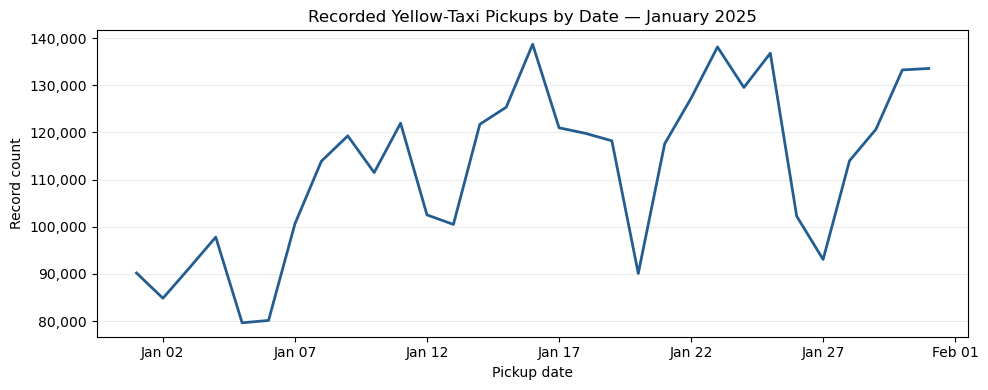

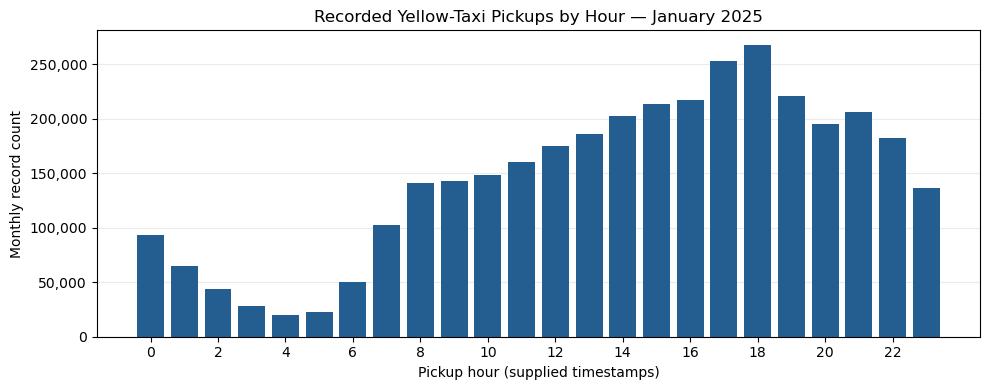

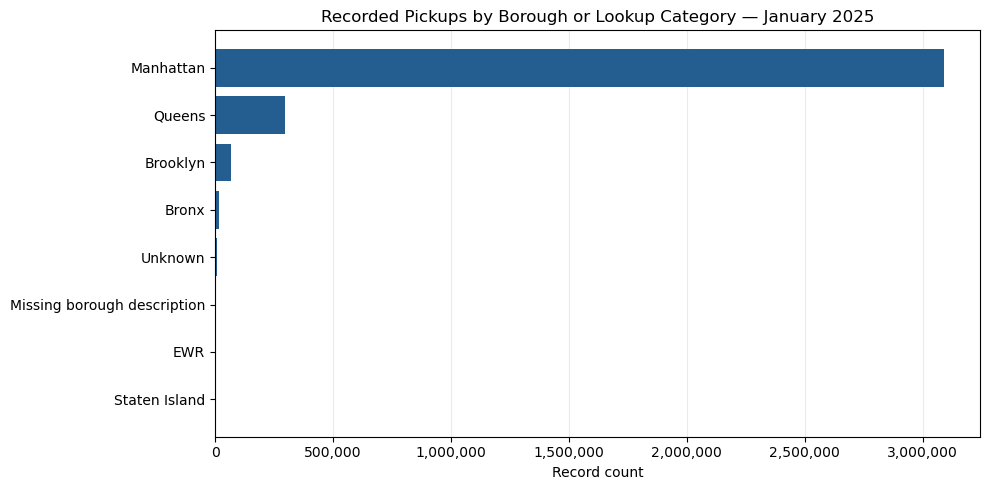

Charts saved to: C:\Users\ferri\anaconda_projects\DSC680\Week_09\NYC_Taxi\reports\figures


In [5]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import StrMethodFormatter

figure_dir = Path("../reports/figures")
figure_dir.mkdir(parents=True, exist_ok=True)

# Daily activity
fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(
    daily_counts["pickup_date"],
    daily_counts["record_count"],
    color="#245e91",
    linewidth=2
)

ax.set(
    title="Recorded Yellow-Taxi Pickups by Date — January 2025",
    xlabel="Pickup date",
    ylabel="Record count"
)

ax.xaxis.set_major_locator(mdates.DayLocator(interval=5))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
fig.savefig(figure_dir / "daily_pickups_2025-01.png", dpi=150)
plt.show()
plt.close(fig)

# Hourly activity across the entire month
fig, ax = plt.subplots(figsize=(10, 4))

ax.bar(
    hourly_counts["pickup_hour"],
    hourly_counts["record_count"],
    color="#245e91"
)

ax.set(
    title="Recorded Yellow-Taxi Pickups by Hour — January 2025",
    xlabel="Pickup hour (supplied timestamps)",
    ylabel="Monthly record count"
)

ax.set_xticks(range(0, 24, 2))
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

fig.tight_layout()
fig.savefig(figure_dir / "hourly_pickups_2025-01.png", dpi=150)
plt.show()
plt.close(fig)

# Preserve every borough and lookup category.
borough_plot = borough_counts.sort_values("record_count")

fig, ax = plt.subplots(figsize=(10, 5))

ax.barh(
    borough_plot["pickup_borough"],
    borough_plot["record_count"],
    color="#245e91"
)

ax.set(
    title="Recorded Pickups by Borough or Lookup Category — January 2025",
    xlabel="Record count",
    ylabel=""
)

ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

fig.tight_layout()
fig.savefig(figure_dir / "borough_pickups_2025-01.png", dpi=150)
plt.show()
plt.close(fig)

print(f"Charts saved to: {figure_dir.resolve()}")

### 3. Findings and Interpretation

Manhattan accounted for 88.89% of recorded January pickups, followed
by Queens at 8.49%. These percentages describe the yellow-taxi records
in this dataset, not all transportation activity in either borough.

The largest hourly count occurred from 18:00 through 18:59, with
267,951 records across the month. January 16 had the largest daily
count, with 138,711 records.

Unknown, missing borough descriptions, and EWR remain separate
lookup categories. Smaller categories may be difficult to distinguish
in the chart because Manhattan accounts for most records; their exact
counts remain available in the summary table.

All summaries reconcile to 3,475,204 January records. Flagged records
remain included, and the analysis does not establish the causes of
the observed patterns. One month of data is insufficient to establish
annual seasonality.